# MAI101 – Machine Learning Assignment 1

                                                            Professor : Reid Kerr
                                                            Submitted by: Vishvaja Umasankar

## 1.Exploratory Data Analysis

In [240]:
import pandas as pd
import numpy as np 
df = pd.read_csv("MAI101_Assignment1_used_vehicle_data.csv")

### 1.1 Dataset Size and Structure

In [241]:
df.head()

,MAKE,MODEL,YEAR,KILOMETRES,ENGINE_SIZE,FUEL_TYPE,TRANSMISSION,BODY_TYPE,DRIVETRAIN,DOORS,SEATS,ACCIDENTS,OWNERS,COLOUR,LISTING_DAYS,HAS_WARRANTY,CONDITION_SCORE,SELLING_PRICE
0,Mercedes-Benz,GLA,2010,193254.0,1.8,Gasoline,Automatic,Sedan,AWD,4.0,5.0,0.0,2.0,Red,40.0,0.0,7.0,39257.66
1,Nissan,Frontier,2021,58800.0,5.7,Gasoline,Automatic,SUV,FWD,4.0,5.0,1.0,3.0,Black,71.0,0.0,2.0,42237.72
2,Hyundai,Palisade,2017,127591.0,2.0,Hybrid,Dual-Clutch,SUV,AWD,5.0,6.0,1.0,1.0,Brown,23.0,0.0,7.0,45240.28
3,BMW,X3,2015,170698.0,2.5,Gasoline,Automatic,Sedan,4WD,4.0,7.0,1.0,2.0,Silver,94.0,0.0,9.0,46287.33
4,Honda,Accord,2022,NaN,1.6,Gasoline,Automatic,SUV,AWD,4.0,5.0,1.0,2.0,Grey,44.0,0.0,6.0,54516.51


In [242]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1815 entries, 0 to 1814
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   MAKE             1815 non-null   object 
 1   MODEL            1815 non-null   object 
 2   YEAR             1815 non-null   int64  
 3   KILOMETRES       1779 non-null   float64
 4   ENGINE_SIZE      1761 non-null   float64
 5   FUEL_TYPE        1796 non-null   object 
 6   TRANSMISSION     1788 non-null   object 
 7   BODY_TYPE        1797 non-null   object 
 8   DRIVETRAIN       1770 non-null   object 
 9   DOORS            1797 non-null   float64
 10  SEATS            1797 non-null   float64
 11  ACCIDENTS        1779 non-null   float64
 12  OWNERS           1778 non-null   float64
 13  COLOUR           1761 non-null   object 
 14  LISTING_DAYS     1797 non-null   float64
 15  HAS_WARRANTY     1788 non-null   float64
 16  CONDITION_SCORE  1778 non-null   float64
 17  SELLING_PRICE 

In [243]:
df.shape

(1815, 18)

#### The Dataset contains 1815 rows and 18 columns.Each row represents a vehicle, and the columns contain vehicle details and the selling price. The SELLING_PRICE is the Target variable.

### 1.2 Variable Type

In [244]:
df.dtypes

MAKE                object
MODEL               object
YEAR                 int64
KILOMETRES         float64
ENGINE_SIZE        float64
FUEL_TYPE           object
TRANSMISSION        object
BODY_TYPE           object
DRIVETRAIN          object
DOORS              float64
SEATS              float64
ACCIDENTS          float64
OWNERS             float64
COLOUR              object
LISTING_DAYS       float64
HAS_WARRANTY       float64
CONDITION_SCORE    float64
SELLING_PRICE      float64
dtype: object

#### Categorical:MAKE,MODEL,FUEL_TYPE,TRANSMISSION,BODY_TYPE,DRIVETRAIN,COLOUR

#### Numerical:YEAR,KILOMETRES,ENGINE_SIZE,DOORS,SEATS,ACCIDENTS,OWNERS,LISTING_DAYS,HAS_WARRANTY,CONDITION_SCORE,SELLING_PRICE

#### Binary categorical (coded numerically): HAS_WARRANTY (1 = Yes, 0 = No)

### 1.3 Missing Values and Duplicates

In [245]:
df.isna().sum()

MAKE                0
MODEL               0
YEAR                0
KILOMETRES         36
ENGINE_SIZE        54
FUEL_TYPE          19
TRANSMISSION       27
BODY_TYPE          18
DRIVETRAIN         45
DOORS              18
SEATS              18
ACCIDENTS          36
OWNERS             37
COLOUR             54
LISTING_DAYS       18
HAS_WARRANTY       27
CONDITION_SCORE    37
SELLING_PRICE      10
dtype: int64

In [246]:
df.duplicated().sum()

np.int64(15)

#### There are 15 duplicates and many missing values in several columns.

### 1.4 Invalids/Outliers

In [247]:
df[df["KILOMETRES"]<0]

,MAKE,MODEL,YEAR,KILOMETRES,ENGINE_SIZE,FUEL_TYPE,TRANSMISSION,BODY_TYPE,DRIVETRAIN,DOORS,SEATS,ACCIDENTS,OWNERS,COLOUR,LISTING_DAYS,HAS_WARRANTY,CONDITION_SCORE,SELLING_PRICE
80,Toyota,Tundra,2010,-222292.0,1.8,Electric,CVT,Hatchback,AWD,5.0,5.0,0.0,1.0,White,50.0,1.0,6.0,29945.90
100,Nissan,Frontier,2012,-189083.0,NaN,Gasoline,Automatic,Sedan,FWD,4.0,4.0,1.0,2.0,Black,19.0,1.0,5.0,22889.54
340,Subaru,Crosstrek,2023,-23025.0,5.7,Diesel,CVT,SUV,RWD,5.0,5.0,1.0,1.0,Silver,34.0,0.0,5.0,58493.40
407,Mini,Countryman,2021,-72267.0,3.6,Gasoline,Manual,Coupe,FWD,2.0,5.0,0.0,2.0,Green,97.0,1.0,7.0,64853.55
1027,Toyota,Camry,2016,-138052.0,3.6,Gasoline,Automatic,Coupe,FWD,4.0,7.0,1.0,1.0,Orange,60.0,1.0,7.0,36933.35
1334,Mitsubishi,Eclipse Cross,2017,-114706.0,3.3,Gasoline,Dual-Clutch,Hatchback,4WD,4.0,7.0,1.0,2.0,Black,105.0,1.0,8.0,40498.82
1372,Volkswagen,Golf,2012,-272858.0,2.0,Gasoline,CVT,SUV,AWD,5.0,5.0,NaN,1.0,Silver,105.0,1.0,8.0,29452.98
1771,RAM,2500,2015,-188370.0,1.8,Gasoline,Automatic,Hatchback,AWD,4.0,5.0,0.0,1.0,Red,29.0,1.0,8.0,34485.70


In [248]:
(df["KILOMETRES"]<0).sum()

np.int64(8)

In [249]:
df[df["KILOMETRES"] > 300000]

,MAKE,MODEL,YEAR,KILOMETRES,ENGINE_SIZE,FUEL_TYPE,TRANSMISSION,BODY_TYPE,DRIVETRAIN,DOORS,SEATS,ACCIDENTS,OWNERS,COLOUR,LISTING_DAYS,HAS_WARRANTY,CONDITION_SCORE,SELLING_PRICE
294,Honda,Odyssey,2012,956421.0,1.8,Gasoline,Manual,Sedan,FWD,4.0,7.0,0.0,3.0,Blue,74.0,0.0,10.0,18572.52
333,Dodge,Charger,2010,308960.0,1.5,Gasoline,Automatic,Coupe,AWD,4.0,5.0,2.0,2.0,White,78.0,0.0,9.0,10405.03
384,Toyota,Tundra,2010,539443.0,1.8,Gasoline,Dual-Clutch,SUV,AWD,4.0,7.0,1.0,1.0,Silver,73.0,0.0,9.0,27832.45
455,Subaru,Outback,2023,680104.0,2.4,Gasoline,CVT,Truck,FWD,4.0,5.0,1.0,2.0,Blue,24.0,1.0,9.0,60367.00
512,BMW,7 Series,2010,331064.0,1.6,Plug-in Hybrid,Manual,Truck,4WD,5.0,5.0,0.0,2.0,Orange,13.0,0.0,7.0,42701.18
525,Honda,Civic,2010,304819.0,6.2,Gasoline,CVT,SUV,AWD,4.0,6.0,1.0,1.0,Silver,22.0,1.0,8.0,25584.14
582,Toyota,Sienna,2018,954967.0,1.8,Hybrid,Automatic,Truck,AWD,4.0,7.0,1.0,1.0,Blue,47.0,0.0,5.0,48625.22
666,lexus,RX,2010,319336.0,NaN,Gasoline,NaN,SUV,FWD,4.0,8.0,1.0,1.0,White,28.0,0.0,5.0,25694.50
845,GMC,Yukon,2017,707923.0,3.0,Gasoline,Dual-Clutch,Hatchback,AWD,4.0,7.0,0.0,2.0,Grey,85.0,1.0,10.0,40865.91
1137,Chevrolet,Tahoe,2010,315839.0,3.0,Gasoline,Automatic,NaN,FWD,4.0,5.0,0.0,3.0,Black,106.0,0.0,8.0,10312.10


In [250]:
(df["KILOMETRES"] > 300000).sum()

np.int64(13)

In [251]:
df[(df["CONDITION_SCORE"]<1) | (df["CONDITION_SCORE"]>10)]

,MAKE,MODEL,YEAR,KILOMETRES,ENGINE_SIZE,FUEL_TYPE,TRANSMISSION,BODY_TYPE,DRIVETRAIN,DOORS,SEATS,ACCIDENTS,OWNERS,COLOUR,LISTING_DAYS,HAS_WARRANTY,CONDITION_SCORE,SELLING_PRICE
193,Nissan,Murano,2018,135339.0,2.5,Gasoline,Automatic,SUV,AWD,4.0,2.0,0.0,3.0,Grey,30.0,1.0,0.0,43721.42
540,Hyundai,Elantra,2023,11751.0,1.5,Gasoline,Automatic,Sedan,FWD,4.0,8.0,0.0,1.0,Silver,5.0,1.0,11.0,55208.15
611,Chevrolet,Tahoe,2023,30592.0,3.0,Hybrid,Automatic,Hatchback,RWD,4.0,5.0,2.0,3.0,Black,103.0,0.0,11.0,45789.76
1142,RAM,ProMaster,2020,49962.0,2.0,Gasoline,CVT,Coupe,RWD,5.0,5.0,0.0,1.0,Grey,6.0,0.0,0.0,40637.76


In [252]:
((df["CONDITION_SCORE"]<1) | (df["CONDITION_SCORE"]>10)).sum()

np.int64(4)

In [253]:
df[df["ENGINE_SIZE"]==0]

,MAKE,MODEL,YEAR,KILOMETRES,ENGINE_SIZE,FUEL_TYPE,TRANSMISSION,BODY_TYPE,DRIVETRAIN,DOORS,SEATS,ACCIDENTS,OWNERS,COLOUR,LISTING_DAYS,HAS_WARRANTY,CONDITION_SCORE,SELLING_PRICE
563,Audi,Q5,2011,187055.0,0.0,Gasoline,Automatic,SUV,FWD,5.0,5.0,3.0,2.0,Red,19.0,0.0,9.0,38875.00
726,Mazda,Mazda6,2018,74912.0,0.0,Gasoline,Automatic,SUV,RWD,4.0,5.0,0.0,3.0,Gold,77.0,0.0,9.0,51459.70
861,Volvo,XC60,2018,90865.0,0.0,Gasoline,CVT,SUV,4WD,4.0,5.0,2.0,2.0,Brown,30.0,1.0,8.0,56934.43
1255,Kia,Forte,2012,183731.0,0.0,Diesel,Automatic,Hatchback,4WD,4.0,5.0,0.0,1.0,Grey,44.0,0.0,5.0,21791.68
1356,Mazda,MX-5,2012,242859.0,0.0,Gasoline,Automatic,Truck,RWD,4.0,5.0,1.0,1.0,Silver,9.0,0.0,8.0,27592.75


In [254]:
df[df["LISTING_DAYS"] < 0]

,MAKE,MODEL,YEAR,KILOMETRES,ENGINE_SIZE,FUEL_TYPE,TRANSMISSION,BODY_TYPE,DRIVETRAIN,DOORS,SEATS,ACCIDENTS,OWNERS,COLOUR,LISTING_DAYS,HAS_WARRANTY,CONDITION_SCORE,SELLING_PRICE
687,Mazda,CX-30,2023,6020.0,1.8,Diesel,Automatic,SUV,FWD,2.0,5.0,0.0,1.0,Black,-6.0,0.0,8.0,67319.37
859,Hyundai,Palisade,2020,81354.0,1.6,Electric,CVT,SUV,4WD,4.0,5.0,0.0,3.0,Brown,-5.0,1.0,6.0,49547.18
1506,Hyundai,Venue,2012,160223.0,2.5,Diesel,Automatic,Coupe,FWD,4.0,5.0,0.0,NaN,White,-119.0,0.0,9.0,27004.05


#### 13 vehicles had more than 300,000 kilometres and 8 vehicles had negative values,4 condition scores were outside the valid range of 1–10, and 5 zero engine-size values were treated as suspicious.These observations were retained because there was insufficient evidence to confirm that they were data errors.

### 1.5 Distributions of Important Numerical Variables

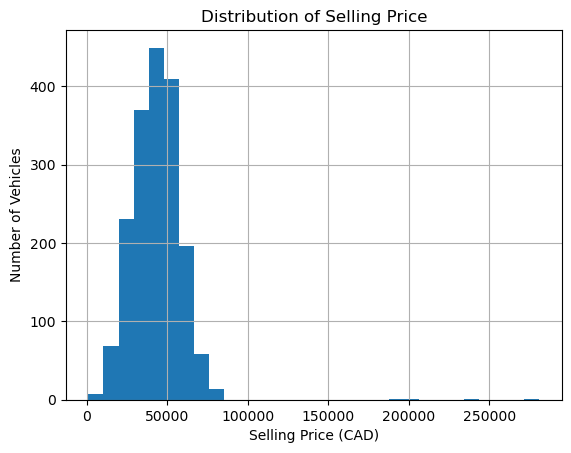

In [255]:
import matplotlib.pyplot as plt

df["SELLING_PRICE"].hist(bins=30)
plt.title("Distribution of Selling Price")
plt.xlabel("Selling Price (CAD)")
plt.ylabel("Number of Vehicles")
plt.show()

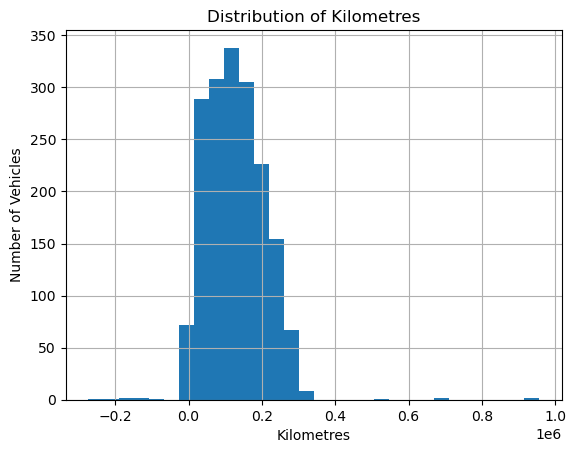

In [256]:
df["KILOMETRES"].hist(bins=30)
plt.title("Distribution of Kilometres")
plt.xlabel("Kilometres")
plt.ylabel("Number of Vehicles")
plt.show()

### Distribution of Numerical Variables

The selling price histogram shows that most vehicles are priced in the lower-to-middle price ranges, while a few vehicles have much higher prices. This indicates a right-skewed distribution, which may make some prices harder for the model to predict accurately.

The kilometres histogram shows that most vehicles have lower kilometre values, but a few have extremely high values. Negative kilometre values were also identified, so these invalid values need to be handled during data preparation.

### 1.6 Relationships Between Predictors and Selling Price

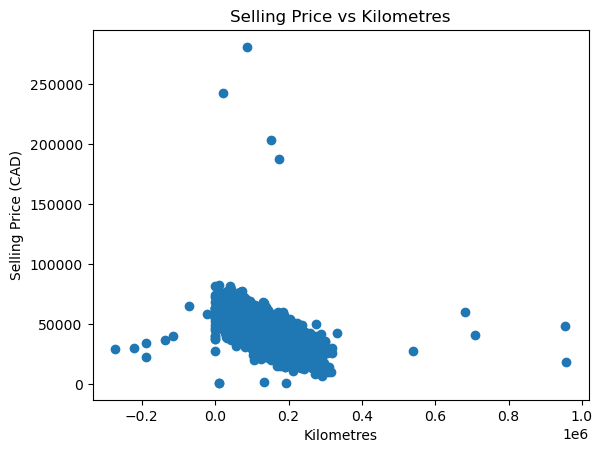

In [257]:
plt.scatter(df["KILOMETRES"], df["SELLING_PRICE"])
plt.xlabel("Kilometres")
plt.ylabel("Selling Price (CAD)")
plt.title("Selling Price vs Kilometres")
plt.show()

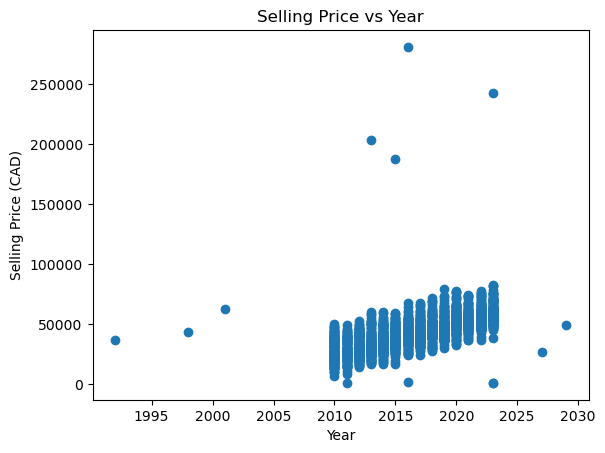

In [258]:
plt.scatter(df["YEAR"], df["SELLING_PRICE"])
plt.xlabel("Year")
plt.ylabel("Selling Price (CAD)")
plt.title("Selling Price vs Year")
plt.show()

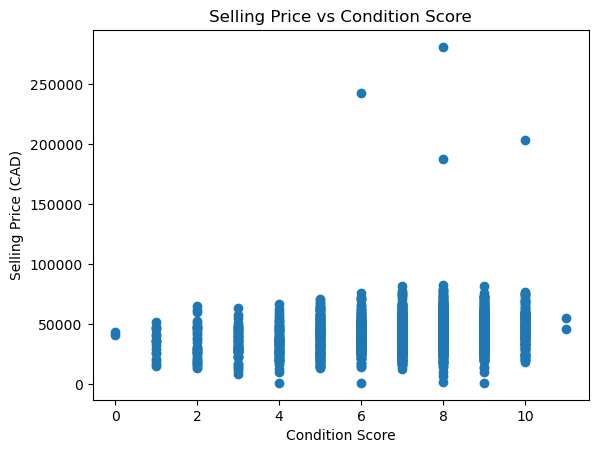

In [259]:
plt.scatter(df["CONDITION_SCORE"], df["SELLING_PRICE"])
plt.xlabel("Condition Score")
plt.ylabel("Selling Price (CAD)")
plt.title("Selling Price vs Condition Score")
plt.show()

#### The scatter plots show that vehicles with higher kilometres generally have lower selling prices, while newer vehicles tend to have higher prices. Vehicles with better condition scores also show some tendency to have higher prices, although the relationship is not always clear. These patterns suggest that year, kilometres, and condition score may be useful predictors when estimating a vehicle's selling price.

### 1.7 Important Categorical Variables

In [260]:
df["MAKE"].value_counts(dropna=False).head(10)

MAKE
Toyota           210
Honda            184
Ford             150
Chevrolet        126
Hyundai          114
Nissan           108
BMW               90
Kia               84
Mercedes-Benz     75
Mazda             64
Name: count, dtype: int64

In [261]:
df["FUEL_TYPE"].value_counts(dropna=False)

FUEL_TYPE
Gasoline          1287
Hybrid             197
Diesel             145
Electric            98
Plug-in Hybrid      49
NaN                 19
GASOLINE            10
gasoline             5
hybrid               3
diesel               1
HYBRID               1
Name: count, dtype: int64

In [262]:
df["TRANSMISSION"].value_counts(dropna=False)

TRANSMISSION
Automatic      1240
CVT             282
Manual          136
Dual-Clutch     115
NaN              27
Auto              3
auto              3
AUTOMATIC         3
manual            2
 Manual           2
Automatic         2
Name: count, dtype: int64

In [263]:
df["BODY_TYPE"].value_counts(dropna=False)

BODY_TYPE
SUV          579
Sedan        500
Truck        271
Hatchback    160
Coupe        125
Minivan      100
Wagon         62
NaN           18
Name: count, dtype: int64

In [264]:
df["DRIVETRAIN"].value_counts(dropna=False)

DRIVETRAIN
FWD    715
AWD    541
4WD    272
RWD    242
NaN     45
Name: count, dtype: int64

#### There are inconsistent capitalization and spacing in some categories, such as GASOLINE vs gasoline and Automatic vs automatic.

## 2.Data Preparation

### a. Individual variables

#### 2.1 Creating a clean Dataset

In [265]:
df_clean = df.copy()

In [266]:
df_clean.shape

(1815, 18)

In [267]:
df_clean = df_clean.drop_duplicates()

#### Removed Duplicate Rows 

In [268]:
df_clean.shape

(1800, 18)

#### 2.2 Handling Invalid Inputs

In [269]:
df_clean[df_clean["KILOMETRES"]<0]

,MAKE,MODEL,YEAR,KILOMETRES,ENGINE_SIZE,FUEL_TYPE,TRANSMISSION,BODY_TYPE,DRIVETRAIN,DOORS,SEATS,ACCIDENTS,OWNERS,COLOUR,LISTING_DAYS,HAS_WARRANTY,CONDITION_SCORE,SELLING_PRICE
80,Toyota,Tundra,2010,-222292.0,1.8,Electric,CVT,Hatchback,AWD,5.0,5.0,0.0,1.0,White,50.0,1.0,6.0,29945.90
100,Nissan,Frontier,2012,-189083.0,NaN,Gasoline,Automatic,Sedan,FWD,4.0,4.0,1.0,2.0,Black,19.0,1.0,5.0,22889.54
340,Subaru,Crosstrek,2023,-23025.0,5.7,Diesel,CVT,SUV,RWD,5.0,5.0,1.0,1.0,Silver,34.0,0.0,5.0,58493.40
407,Mini,Countryman,2021,-72267.0,3.6,Gasoline,Manual,Coupe,FWD,2.0,5.0,0.0,2.0,Green,97.0,1.0,7.0,64853.55
1027,Toyota,Camry,2016,-138052.0,3.6,Gasoline,Automatic,Coupe,FWD,4.0,7.0,1.0,1.0,Orange,60.0,1.0,7.0,36933.35
1334,Mitsubishi,Eclipse Cross,2017,-114706.0,3.3,Gasoline,Dual-Clutch,Hatchback,4WD,4.0,7.0,1.0,2.0,Black,105.0,1.0,8.0,40498.82
1372,Volkswagen,Golf,2012,-272858.0,2.0,Gasoline,CVT,SUV,AWD,5.0,5.0,NaN,1.0,Silver,105.0,1.0,8.0,29452.98
1771,RAM,2500,2015,-188370.0,1.8,Gasoline,Automatic,Hatchback,AWD,4.0,5.0,0.0,1.0,Red,29.0,1.0,8.0,34485.70


In [270]:
df_clean = df_clean[~(df_clean["KILOMETRES"] < 0)]

In [271]:
df_clean.shape

(1792, 18)

In [272]:
(df_clean["KILOMETRES"] < 0).sum()

np.int64(0)

#### Removed 8 negative values; missing values remain for later imputation.

In [273]:
df_clean[
    (df_clean["CONDITION_SCORE"] < 1) |
    (df_clean["CONDITION_SCORE"] > 10)
]

,MAKE,MODEL,YEAR,KILOMETRES,ENGINE_SIZE,FUEL_TYPE,TRANSMISSION,BODY_TYPE,DRIVETRAIN,DOORS,SEATS,ACCIDENTS,OWNERS,COLOUR,LISTING_DAYS,HAS_WARRANTY,CONDITION_SCORE,SELLING_PRICE
193,Nissan,Murano,2018,135339.0,2.5,Gasoline,Automatic,SUV,AWD,4.0,2.0,0.0,3.0,Grey,30.0,1.0,0.0,43721.42
540,Hyundai,Elantra,2023,11751.0,1.5,Gasoline,Automatic,Sedan,FWD,4.0,8.0,0.0,1.0,Silver,5.0,1.0,11.0,55208.15
611,Chevrolet,Tahoe,2023,30592.0,3.0,Hybrid,Automatic,Hatchback,RWD,4.0,5.0,2.0,3.0,Black,103.0,0.0,11.0,45789.76
1142,RAM,ProMaster,2020,49962.0,2.0,Gasoline,CVT,Coupe,RWD,5.0,5.0,0.0,1.0,Grey,6.0,0.0,0.0,40637.76


In [171]:
df_clean.loc[
    (df_clean["CONDITION_SCORE"] < 1) |
    (df_clean["CONDITION_SCORE"] > 10),
    "CONDITION_SCORE"
] = np.nan

In [172]:
df_clean["CONDITION_SCORE"].isna().sum()

np.int64(40)

#### Four scores outside the valid 1–10 range changed to missing values.

In [173]:
df_clean[df_clean["ENGINE_SIZE"] == 0][
    ["MAKE", "MODEL", "YEAR", "ENGINE_SIZE", "SELLING_PRICE"]
]

,MAKE,MODEL,YEAR,ENGINE_SIZE,SELLING_PRICE
563,Audi,Q5,2011,0.0,38875.00
726,Mazda,Mazda6,2018,0.0,51459.70
861,Volvo,XC60,2018,0.0,56934.43
1255,Kia,Forte,2012,0.0,21791.68
1356,Mazda,MX-5,2012,0.0,27592.75


In [174]:
df_clean.loc[df_clean["ENGINE_SIZE"] == 0, "ENGINE_SIZE"] = np.nan

In [175]:
df_clean["ENGINE_SIZE"].isna().sum()

np.int64(58)

In [176]:
(df_clean["ENGINE_SIZE"] == 0).sum()

np.int64(0)

#### Five zero values treated as suspicious and changed to missing values

In [177]:
df_clean["YEAR"].describe()

count    1792.000000
mean     2016.469866
std         4.113709
min      1992.000000
25%      2013.000000
50%      2017.000000
75%      2020.000000
max      2029.000000
Name: YEAR, dtype: float64

In [178]:
df_clean["YEAR"].sort_values().head(10)

468     1992
311     1998
610     2001
1308    2010
1293    2010
1283    2010
272     2010
1262    2010
1259    2010
1256    2010
Name: YEAR, dtype: int64

In [179]:
df_clean["YEAR"].value_counts().sort_index().tail(10)

YEAR
2016    125
2017    134
2018    121
2019    134
2020    135
2021    112
2022    142
2023    117
2027      1
2029      1
Name: count, dtype: int64

In [180]:
df_clean.loc[df_clean["YEAR"] > 2023, "YEAR"] = np.nan

In [181]:
df_clean["YEAR"].isna().sum()

np.int64(2)

#### The years 2027 and 2029 were considered suspicious for this used-vehicle dataset and changed to missing values. These missing values were later handled by median imputation during model preprocessing.

#### 2.3 Standardizing categorical Variable 

In [182]:
df_clean["FUEL_TYPE"] = df_clean["FUEL_TYPE"].str.lower().str.strip()

In [183]:
df_clean["FUEL_TYPE"].value_counts(dropna=False)

FUEL_TYPE
gasoline          1283
hybrid             200
diesel             145
electric            97
plug-in hybrid      49
NaN                 18
Name: count, dtype: int64

#### Text was standardized to lowercase, and extra spaces were removed.

In [184]:
df_clean["TRANSMISSION"] = df_clean["TRANSMISSION"].str.lower().str.strip()

In [185]:
df_clean["TRANSMISSION"].value_counts(dropna=False)

TRANSMISSION
automatic      1229
cvt             277
manual          139
dual-clutch     114
NaN              27
auto              6
Name: count, dtype: int64

In [186]:
df_clean["TRANSMISSION"] = df_clean["TRANSMISSION"].replace({
    "auto": "automatic"
})

In [187]:
df_clean["TRANSMISSION"].value_counts(dropna=False)

TRANSMISSION
automatic      1235
cvt             277
manual          139
dual-clutch     114
NaN              27
Name: count, dtype: int64

#### Labels were standardized by trimming spaces, converting to lowercase, and replacing auto with automatic.

In [188]:
df_clean["DRIVETRAIN"].value_counts(dropna=False)

DRIVETRAIN
FWD    704
AWD    535
4WD    270
RWD    238
NaN     45
Name: count, dtype: int64

#### Missing values will be handled by categorical imputation.

In [189]:
df_clean["COLOUR"]= df_clean["COLOUR"].str.strip().str.lower()

In [190]:
df_clean["COLOUR"].value_counts(dropna=False)

COLOUR
white     307
black     285
silver    246
blue      220
grey      212
red       185
brown      93
green      73
gold       65
NaN        54
orange     52
Name: count, dtype: int64

#### Text was standardized to lowercase, and extra spaces were removed; missing values will be imputed.

In [191]:
df_clean["MAKE"]= df_clean["MAKE"].str.strip().str.lower()

In [192]:
df_clean["MAKE"].value_counts(dropna=False)

MAKE
toyota           206
honda            185
ford             151
chevrolet        127
hyundai          114
nissan           108
bmw               90
kia               88
mercedes-benz     74
mazda             66
audi              58
volkswagen        58
dodge             56
ram               43
jeep              42
subaru            42
buick             40
lexus             37
gmc               35
tesla             22
jaguar            22
mini              18
volvo             17
infiniti          16
mitsubishi        16
genesis           15
acura             13
porsche           12
cadillac          11
land rover        10
Name: count, dtype: int64

#### Inconsistent capitalization was standardized to lowercase, and extra spaces were removed.

In [193]:
df_clean["MODEL"].value_counts(dropna=False).head(20)

MODEL
HR-V          37
Pilot         34
Camry         34
Civic         30
RAV4          30
Sienna        30
Accord        26
Tacoma        26
Elantra       24
Highlander    23
Palisade      23
Frontier      23
Corolla       23
Tundra        22
F-150         22
Escape        22
CR-V          21
Explorer      21
Odyssey       21
Camaro        20
Name: count, dtype: int64

#### No specific cleaning transformation was applied; it was retained as a categorical predictor.

In [194]:
df_clean["ACCIDENTS"].value_counts(dropna=False).sort_index()

ACCIDENTS
0.0    1151
1.0     360
2.0     169
3.0      77
NaN      35
Name: count, dtype: int64

#### Missing values will be handled by numerical imputation.

In [195]:
df_clean["OWNERS"].value_counts(dropna=False).sort_index()

OWNERS
1.0    799
2.0    610
3.0    256
4.0     91
NaN     36
Name: count, dtype: int64

#### Missing values will be handled by numerical imputation.

In [196]:
df_clean["HAS_WARRANTY"].value_counts(dropna=False).sort_index()

HAS_WARRANTY
0.0    1015
1.0     750
NaN      27
Name: count, dtype: int64

#### Retained as a binary predictor coded as 0 and 1, missing values will be handled during numerical preprocessing.

In [197]:
df_clean["BODY_TYPE"].value_counts(dropna=False)

BODY_TYPE
SUV          576
Sedan        493
Truck        269
Hatchback    153
Coupe        122
Minivan      100
Wagon         61
NaN           18
Name: count, dtype: int64

In [198]:
df_clean["DOORS"].value_counts(dropna=False)

DOORS
4.0    1170
5.0     412
2.0     152
3.0      40
NaN      18
Name: count, dtype: int64

### b.Data-set Preparation

In [199]:
df_clean["SELLING_PRICE"].isna().sum()

np.int64(9)

In [200]:
df_model = df_clean.dropna(subset=["SELLING_PRICE"]).copy()

#### Missing target values are be excluded from model training and evaluation.

In [201]:
df_model.shape

(1783, 18)

#### 2.4 Separating predictors and target

In [202]:
X = df_model.drop(columns=["SELLING_PRICE", "LISTING_DAYS"])
y = df_model["SELLING_PRICE"]

##### The vehicle details were separated into predictors (`X`), while `SELLING_PRICE` was selected as the target (`y`). `LISTING_DAYS` was excluded because it is unavailable when the vehicle is prepared for sale.

In [203]:
X.shape

(1783, 16)

In [204]:
y.shape

(1783,)

In [205]:
X.columns.tolist()

['MAKE',
 'MODEL',
 'YEAR',
 'KILOMETRES',
 'ENGINE_SIZE',
 'FUEL_TYPE',
 'TRANSMISSION',
 'BODY_TYPE',
 'DRIVETRAIN',
 'DOORS',
 'SEATS',
 'ACCIDENTS',
 'OWNERS',
 'COLOUR',
 'HAS_WARRANTY',
 'CONDITION_SCORE']

#### 2.5 Spliting the Data into Training and Testing Sets

In [206]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [207]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1426, 16), (357, 16), (1426,), (357,))

#### The dataset was divided into training and testing sets, with 80% used for training and 20% reserved for testing. The training set is used to fit the model, while the testing set evaluates its performance on data it did not train on.

In [208]:
numeric_features = [
    "YEAR", "KILOMETRES", "ENGINE_SIZE", "DOORS", "SEATS",
    "ACCIDENTS", "OWNERS", "HAS_WARRANTY", "CONDITION_SCORE"
]

categorical_features = [
    "MAKE", "MODEL", "FUEL_TYPE", "TRANSMISSION",
    "BODY_TYPE", "DRIVETRAIN", "COLOUR"
]

In [209]:
len(numeric_features), len(categorical_features)

(9, 7)

#### 2.6 Preparing the Model Pipeline

In [210]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

In [211]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

#### Missing numerical values were handled using median imputation

In [212]:
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

#### Missing categorical values were filled using the most frequent category. One-hot encoding converted categorical variables into numerical features for the Linear Regression model.

In [213]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

#### A ColumnTransformer was used to apply the appropriate preprocessing to numerical and categorical predictors. This keeps the preparation steps organized and ensures that each type of variable is handled correctly.


## 3.Model 

In [214]:
from sklearn.linear_model import LinearRegression

In [215]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

#### The preprocessing steps were combined with Linear Regression in a pipeline. This ensures that preprocessing was learned from the training data and then applied to the test data without fitting those transformations on the test set.

In [216]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['YEAR', 'KILOMETRES',
                                                   'ENGINE_SIZE', 'DOORS',
                                                   'SEATS', 'ACCIDENTS',
                                                   'OWNERS', 'HAS_WARRANTY',
                                                   'CONDITION_SCORE']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['MAKE', 'MODEL', 'FUEL_TYPE',
                                                   'TRANSMISSION', 'BODY_TYPE',
                                                   'DRIVETRAIN', 'COLOUR'])])),
                ('regressor', LinearRegression())])

In [217]:
y_pred = model.predict(X_test)

In [218]:
y_pred[:5]

array([54318.06966252, 35352.62340628, 64115.58451475, 44535.60678954,
       26175.72031324])

## 4.Evaluation

In [219]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 5084.950816723567
RMSE: 7495.789016902261
R²: 0.7171983545640017


#### The model achieved an MAE of approximately $5,084  and $7,496 of RSME. The higher RMSE suggests that some predictions have larger errors. The R² value of 0.7172 indicates that the model explains about 71.72% of the variation in selling prices in the test dataset. 


### 4.1 Actual vs. Predicted Prices

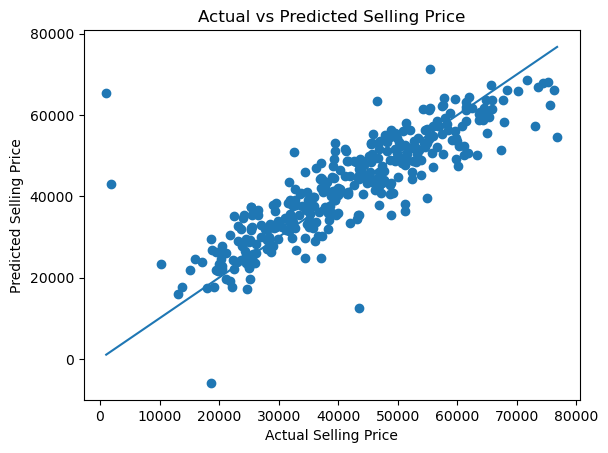

In [220]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted Selling Price")
plt.show()

#### The plot compares actual selling prices with the prices predicted by the model. Points closer to the diagonal line indicate more accurate predictions, while points farther away indicate larger prediction errors.

### 4.2 Residual Analysis

In [221]:
residuals = y_test - y_pred

print(residuals.head())

838    -4498.639663
1498   -9910.903406
237    -6435.924515
812    -5315.106790
791    -6786.270313
Name: SELLING_PRICE, dtype: float64


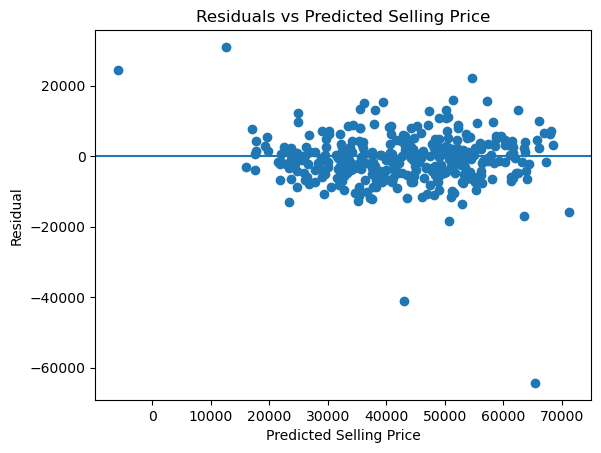

In [222]:
plt.scatter(y_pred, residuals)
plt.axhline(0)
plt.xlabel("Predicted Selling Price")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted Selling Price")
plt.show()

#### Residuals show how much the model overestimated or underestimated each vehicle's selling price. Positive residuals indicate underprediction, while negative residuals indicate overprediction. A random scatter around zero is generally desirable, while visible patterns or large residuals may indicate areas where the model performs less well.


## 5. Overall Evaluation

The Linear Regression model performed reasonably well, with an R² score of 0.7172, meaning it explained about 71.72% of the differences in vehicle selling prices in the test data. The average prediction error (MAE) was around $5,085. The actual-versus-predicted plot shows that most predictions follow the general trend, but some are far from the correct values.

The residual plot also shows that most errors are close to zero, while a few vehicles have much larger errors. This means the model can provide useful price estimates, but it does not predict every vehicle's price accurately.